In [ ]:
from google.colab import files

uploaded = files.upload()

Saving att_faces.zip to att_faces.zip


In [ ]:
import zipfile

with zipfile.ZipFile("/content/att_faces.zip", "r") as zip_ref:
    zip_ref.extractall("/content")

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [ ]:
DATASET_PATH = "/content"

In [ ]:
import os

DATASET_PATH = "/content"

persons = sorted([
    folder
    for folder in os.listdir(DATASET_PATH)
    if folder.startswith("s")
    and folder[1:].isdigit()
    and 1 <= int(folder[1:]) <= 40
    and os.path.isdir(os.path.join(DATASET_PATH, folder))
])

print("Number of individuals:", len(persons))
print("Individuals:", persons)

Number of individuals: 40
Individuals: ['s1', 's10', 's11', 's12', 's13', 's14', 's15', 's16', 's17', 's18', 's19', 's2', 's20', 's21', 's22', 's23', 's24', 's25', 's26', 's27', 's28', 's29', 's3', 's30', 's31', 's32', 's33', 's34', 's35', 's36', 's37', 's38', 's39', 's4', 's40', 's5', 's6', 's7', 's8', 's9']


In [ ]:
total_images = 0
print("Images per individual:\n")
for person in persons:

    person_path = os.path.join(DATASET_PATH, person)

    images = [
        file
        for file in os.listdir(person_path)
        if file.lower().endswith(".pgm")
    ]

    print(f"{person}: {len(images)} images")

    total_images += len(images)
print("\n" + "=" * 40)
print("Total individuals:", len(persons))
print("Total images:", total_images)
print("=" * 40)

Images per individual:

s1: 10 images
s10: 10 images
s11: 10 images
s12: 10 images
s13: 10 images
s14: 10 images
s15: 10 images
s16: 10 images
s17: 10 images
s18: 10 images
s19: 10 images
s2: 10 images
s20: 10 images
s21: 10 images
s22: 10 images
s23: 10 images
s24: 10 images
s25: 10 images
s26: 10 images
s27: 10 images
s28: 10 images
s29: 10 images
s3: 10 images
s30: 10 images
s31: 10 images
s32: 10 images
s33: 10 images
s34: 10 images
s35: 10 images
s36: 10 images
s37: 10 images
s38: 10 images
s39: 10 images
s4: 10 images
s40: 10 images
s5: 10 images
s6: 10 images
s7: 10 images
s8: 10 images
s9: 10 images

Total individuals: 40
Total images: 400


In [ ]:
# ============================================================
# CELL 1 — ENVIRONMENT SETUP
# Lab Assignment 06
# Siamese Neural Network-Based Face Recognition System
# ============================================================
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
print("=" * 60)
print("LAB ASSIGNMENT 06")
print("Siamese Neural Network-Based Face Recognition System")
print("=" * 60)
print("\nTensorFlow Version :", tf.__version__)
print("OpenCV Version     :", cv2.__version__)
print("NumPy Version      :", np.__version__)
print("\nEnvironment setup completed successfully.")

LAB ASSIGNMENT 06
Siamese Neural Network-Based Face Recognition System

TensorFlow Version : 2.20.0
OpenCV Version     : 4.14.0
NumPy Version      : 2.1.3

Environment setup completed successfully.


In [ ]:
# ============================================================
# CELL 2 — PROJECT CONFIGURATION
# ============================================================

# Dataset location in Google Colab
DATASET_PATH = "/content"
# Required image dimensions from the assignment
IMG_HEIGHT = 112
IMG_WIDTH = 92
CHANNELS = 1
# Random seed for reproducibility
RANDOM_SEED = 42
# Model directory
MODEL_DIR = "/content/models"
# Registered users directory
REGISTERED_USERS_DIR = "/content/registered_users"
# Test cases directory
TEST_CASES_DIR = "/content/test_cases"
# Screenshot directory
SCREENSHOT_DIR = "/content/screenshots"
# Create project directories
os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(REGISTERED_USERS_DIR, exist_ok=True)
os.makedirs(TEST_CASES_DIR, exist_ok=True)
os.makedirs(SCREENSHOT_DIR, exist_ok=True)
print("=" * 60)
print("PROJECT CONFIGURATION")
print("=" * 60)
print("Dataset path       :", DATASET_PATH)
print("Image height       :", IMG_HEIGHT)
print("Image width        :", IMG_WIDTH)
print("Input shape        :", (IMG_HEIGHT, IMG_WIDTH, CHANNELS))
print("Random seed        :", RANDOM_SEED)
print("Model directory    :", MODEL_DIR)
print("Registered users   :", REGISTERED_USERS_DIR)
print("Test cases         :", TEST_CASES_DIR)
print("Screenshot folder  :", SCREENSHOT_DIR)

PROJECT CONFIGURATION
Dataset path       : /content
Image height       : 112
Image width        : 92
Input shape        : (112, 92, 1)
Random seed        : 42
Model directory    : /content/models
Registered users   : /content/registered_users
Test cases         : /content/test_cases
Screenshot folder  : /content/screenshots


In [ ]:
# ============================================================
# CELL 3 — DATASET FOLDER IDENTIFICATION
# ============================================================
# Identify folders s1 through s40
persons = sorted(
    [
        folder
        for folder in os.listdir(DATASET_PATH)
        if folder.startswith("s")
        and folder[1:].isdigit()
        and 1 <= int(folder[1:]) <= 40
        and os.path.isdir(os.path.join(DATASET_PATH, folder))
    ],
    key=lambda x: int(x[1:])
)
print("=" * 60)
print("DATASET FOLDER IDENTIFICATION")
print("=" * 60)
print("Number of individuals:", len(persons))
print("\nIndividuals:")
print(persons)

DATASET FOLDER IDENTIFICATION
Number of individuals: 40

Individuals:
['s1', 's2', 's3', 's4', 's5', 's6', 's7', 's8', 's9', 's10', 's11', 's12', 's13', 's14', 's15', 's16', 's17', 's18', 's19', 's20', 's21', 's22', 's23', 's24', 's25', 's26', 's27', 's28', 's29', 's30', 's31', 's32', 's33', 's34', 's35', 's36', 's37', 's38', 's39', 's40']


In [ ]:
# ============================================================
# CELL 4 — DATASET STATISTICS
# ============================================================

image_counts = {}
total_images = 0
print("=" * 60)
print("DATASET STATISTICS")
print("=" * 60)
for person in persons:
    person_path = os.path.join(DATASET_PATH, person)

    images = sorted([
        file
        for file in os.listdir(person_path)
        if file.lower().endswith(".pgm")
    ])
    image_counts[person] = len(images)
    total_images += len(images)
    print(f"{person:>4} : {len(images):>2} images")
print("\n" + "=" * 60)
print("SUMMARY")
print("=" * 60)
print("Total individuals :", len(persons))
print("Total images      :", total_images)
print("\nImages per person:")
print("Minimum:", min(image_counts.values()))
print("Maximum:", max(image_counts.values()))
print("Average:", np.mean(list(image_counts.values())))

DATASET STATISTICS
  s1 : 10 images
  s2 : 10 images
  s3 : 10 images
  s4 : 10 images
  s5 : 10 images
  s6 : 10 images
  s7 : 10 images
  s8 : 10 images
  s9 : 10 images
 s10 : 10 images
 s11 : 10 images
 s12 : 10 images
 s13 : 10 images
 s14 : 10 images
 s15 : 10 images
 s16 : 10 images
 s17 : 10 images
 s18 : 10 images
 s19 : 10 images
 s20 : 10 images
 s21 : 10 images
 s22 : 10 images
 s23 : 10 images
 s24 : 10 images
 s25 : 10 images
 s26 : 10 images
 s27 : 10 images
 s28 : 10 images
 s29 : 10 images
 s30 : 10 images
 s31 : 10 images
 s32 : 10 images
 s33 : 10 images
 s34 : 10 images
 s35 : 10 images
 s36 : 10 images
 s37 : 10 images
 s38 : 10 images
 s39 : 10 images
 s40 : 10 images

SUMMARY
Total individuals : 40
Total images      : 400

Images per person:
Minimum: 10
Maximum: 10
Average: 10.0


In [ ]:
# ============================================================
# CELL 5 — DATASET FOLDER STRUCTURE
# ============================================================
print("=" * 60)
print("DATASET FOLDER STRUCTURE")
print("=" * 60)
for person in persons[:5]:
    person_path = os.path.join(DATASET_PATH, person)
    images = sorted([
        file
        for file in os.listdir(person_path)
        if file.lower().endswith(".pgm")
    ])
    print(f"\n{person}/")
    for image in images:
        print(f"    └── {image}")
print("\n...")
print(f"\nTotal identity folders: {len(persons)}")
print(f"Total images: {total_images}")

DATASET FOLDER STRUCTURE

s1/
    └── 1.pgm
    └── 10.pgm
    └── 2.pgm
    └── 3.pgm
    └── 4.pgm
    └── 5.pgm
    └── 6.pgm
    └── 7.pgm
    └── 8.pgm
    └── 9.pgm

s2/
    └── 1.pgm
    └── 10.pgm
    └── 2.pgm
    └── 3.pgm
    └── 4.pgm
    └── 5.pgm
    └── 6.pgm
    └── 7.pgm
    └── 8.pgm
    └── 9.pgm

s3/
    └── 1.pgm
    └── 10.pgm
    └── 2.pgm
    └── 3.pgm
    └── 4.pgm
    └── 5.pgm
    └── 6.pgm
    └── 7.pgm
    └── 8.pgm
    └── 9.pgm

s4/
    └── 1.pgm
    └── 10.pgm
    └── 2.pgm
    └── 3.pgm
    └── 4.pgm
    └── 5.pgm
    └── 6.pgm
    └── 7.pgm
    └── 8.pgm
    └── 9.pgm

s5/
    └── 1.pgm
    └── 10.pgm
    └── 2.pgm
    └── 3.pgm
    └── 4.pgm
    └── 5.pgm
    └── 6.pgm
    └── 7.pgm
    └── 8.pgm
    └── 9.pgm

...

Total identity folders: 40
Total images: 400


In [ ]:
# ============================================================
# CELL 6 — LOAD A SINGLE FACE IMAGE
# ============================================================
sample_person = "s1"
sample_image_name = "1.pgm"
sample_image_path = os.path.join(
    DATASET_PATH,
    sample_person,
    sample_image_name
)
sample_image = cv2.imread(
    sample_image_path,
    cv2.IMREAD_GRAYSCALE
)
print("=" * 60)
print("SINGLE IMAGE LOADING TEST")
print("=" * 60)
print("Image path :", sample_image_path)
print("Image shape:", sample_image.shape)
print("Data type  :", sample_image.dtype)
print("Min pixel  :", sample_image.min())
print("Max pixel  :", sample_image.max())

SINGLE IMAGE LOADING TEST
Image path : /content/s1/1.pgm
Image shape: (112, 92)
Data type  : uint8
Min pixel  : 11
Max pixel  : 234


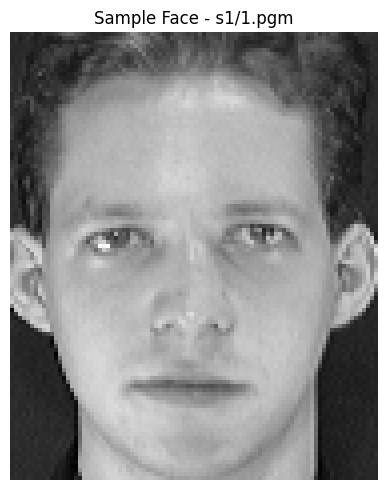

In [ ]:
# ============================================================
# CELL 7 — DISPLAY SINGLE FACE IMAGE
# ============================================================
plt.figure(figsize=(5, 5))
plt.imshow(sample_image, cmap="gray")
plt.title(
    f"Sample Face - {sample_person}/{sample_image_name}"
)
plt.axis("off")
plt.tight_layout()
plt.show()

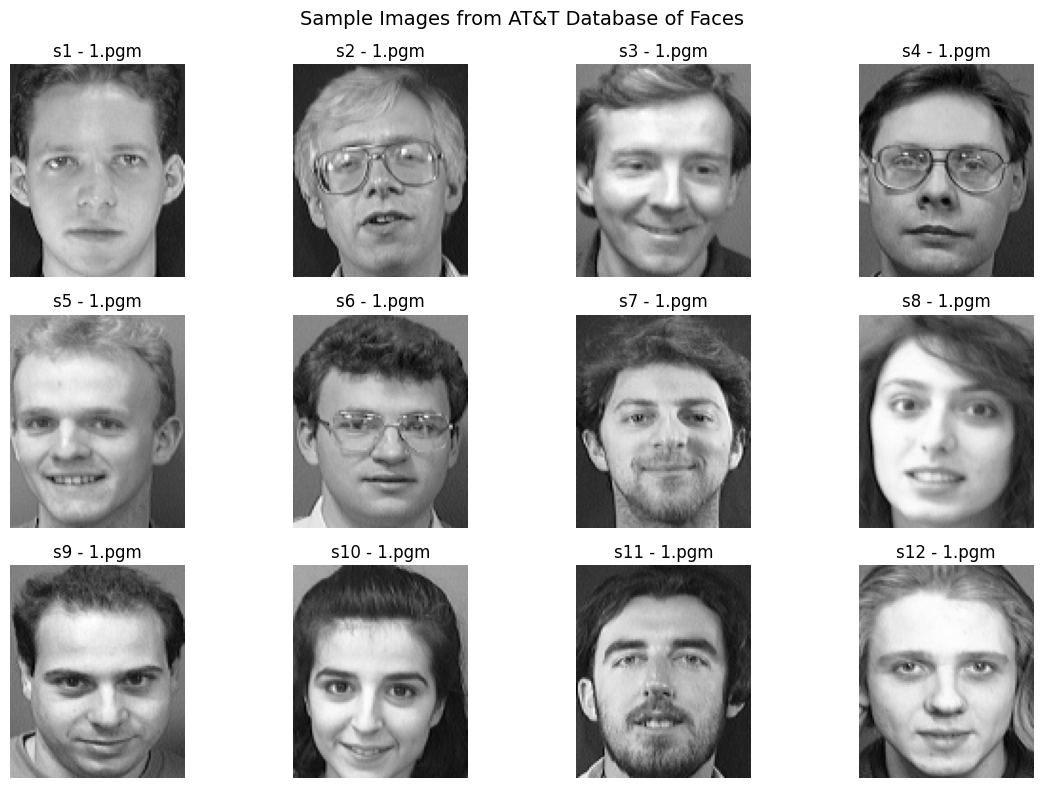

In [ ]:
# ============================================================
# CELL 8 — DISPLAY SAMPLE FACES
# ============================================================
plt.figure(figsize=(12, 8))
sample_persons = persons[:12]
for i, person in enumerate(sample_persons):
    person_path = os.path.join(
        DATASET_PATH,
        person
    )
    image_files = sorted([
        file
        for file in os.listdir(person_path)
        if file.lower().endswith(".pgm")
    ])
    image_path = os.path.join(
        person_path,
        image_files[0]
    )
    image = cv2.imread(
        image_path,
        cv2.IMREAD_GRAYSCALE
    )
    plt.subplot(3, 4, i + 1)
    plt.imshow(image, cmap="gray")
    plt.title(f"{person} - {image_files[0]}")
    plt.axis("off")
plt.suptitle(
    "Sample Images from AT&T Database of Faces",
    fontsize=14
)
plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# CELL 9 — IMAGE PREPROCESSING FUNCTION
# ============================================================
def preprocess_image(image_path):
    # Load image in grayscale
    image = cv2.imread(
        image_path,
        cv2.IMREAD_GRAYSCALE
    )
    if image is None:
        raise ValueError(
            f"Unable to read image: {image_path}"
        )
    # Resize to required dimensions
    image = cv2.resize(
        image,
        (IMG_WIDTH, IMG_HEIGHT)
    )
    # Normalize pixel values from [0,255] to [0,1]
    image = image.astype("float32") / 255.0
    # Add channel dimension
    image = np.expand_dims(
        image,
        axis=-1
    )
    return image
print("Preprocessing function created successfully.")
print(
    "Output shape will be:",
    (IMG_HEIGHT, IMG_WIDTH, CHANNELS)
)

Preprocessing function created successfully.
Output shape will be: (112, 92, 1)


In [ ]:
# ============================================================
# CELL 10 — TEST IMAGE PREPROCESSING
# ============================================================
processed_sample = preprocess_image(
    sample_image_path
)
print("=" * 60)
print("PREPROCESSING TEST")
print("=" * 60)
print("Original image shape :", sample_image.shape)
print("Processed image shape:", processed_sample.shape)
print("\nProcessed data type   :", processed_sample.dtype)
print("Minimum pixel value  :", processed_sample.min())
print("Maximum pixel value  :", processed_sample.max())

PREPROCESSING TEST
Original image shape : (112, 92)
Processed image shape: (112, 92, 1)

Processed data type   : float32
Minimum pixel value  : 0.043137256
Maximum pixel value  : 0.91764706


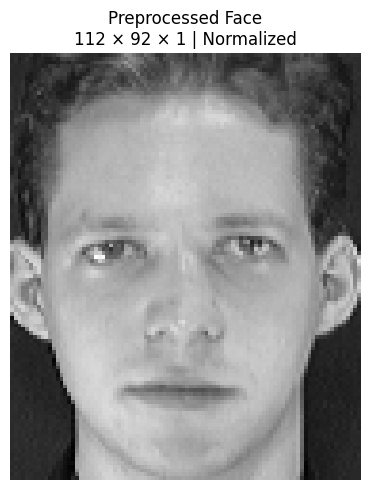

In [ ]:
# ============================================================
# CELL 11 — VISUALIZE PREPROCESSED IMAGE
# ============================================================
plt.figure(figsize=(5, 5))
plt.imshow(
    processed_sample.squeeze(),
    cmap="gray"
)
plt.title(
    "Preprocessed Face\n112 × 92 × 1 | Normalized"
)
plt.axis("off")
plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# CELL 12 — LOAD ENTIRE DATASET
# ============================================================

def load_dataset(dataset_path, persons):
    images = []
    labels = []
    for label, person in enumerate(persons):
        person_path = os.path.join(
            dataset_path,
            person
        )
        image_files = sorted([
            file
            for file in os.listdir(person_path)
            if file.lower().endswith(".pgm")
        ])
        for image_name in image_files:
            image_path = os.path.join(
                person_path,
                image_name
            )
            image = preprocess_image(
                image_path
            )
            images.append(image)
            labels.append(label)
    images = np.array(
        images,
        dtype=np.float32
    )
    labels = np.array(
        labels,
        dtype=np.int32
    )
    return images, labels
X, y = load_dataset(
    DATASET_PATH,
    persons
)
print("=" * 60)
print("ENTIRE DATASET LOADED")
print("=" * 60)
print("Images shape :", X.shape)
print("Labels shape :", y.shape)
print("Data type    :", X.dtype)
print("Min value    :", X.min())
print("Max value    :", X.max())

ENTIRE DATASET LOADED
Images shape : (400, 112, 92, 1)
Labels shape : (400,)
Data type    : float32
Min value    : 0.0
Max value    : 0.9843137


In [ ]:
# ============================================================
# CELL 13 — VERIFY LABEL DISTRIBUTION
# ============================================================
unique_labels, counts = np.unique(
    y,
    return_counts=True
)
print("=" * 60)
print("LABEL DISTRIBUTION")
print("=" * 60)
for label, count in zip(unique_labels, counts):
    print(
        f"Label {label:2d} ({persons[label]:>3}) : "
        f"{count} images"
    )
print("\nTotal classes:", len(unique_labels))
print("Total images :", np.sum(counts))

LABEL DISTRIBUTION
Label  0 ( s1) : 10 images
Label  1 ( s2) : 10 images
Label  2 ( s3) : 10 images
Label  3 ( s4) : 10 images
Label  4 ( s5) : 10 images
Label  5 ( s6) : 10 images
Label  6 ( s7) : 10 images
Label  7 ( s8) : 10 images
Label  8 ( s9) : 10 images
Label  9 (s10) : 10 images
Label 10 (s11) : 10 images
Label 11 (s12) : 10 images
Label 12 (s13) : 10 images
Label 13 (s14) : 10 images
Label 14 (s15) : 10 images
Label 15 (s16) : 10 images
Label 16 (s17) : 10 images
Label 17 (s18) : 10 images
Label 18 (s19) : 10 images
Label 19 (s20) : 10 images
Label 20 (s21) : 10 images
Label 21 (s22) : 10 images
Label 22 (s23) : 10 images
Label 23 (s24) : 10 images
Label 24 (s25) : 10 images
Label 25 (s26) : 10 images
Label 26 (s27) : 10 images
Label 27 (s28) : 10 images
Label 28 (s29) : 10 images
Label 29 (s30) : 10 images
Label 30 (s31) : 10 images
Label 31 (s32) : 10 images
Label 32 (s33) : 10 images
Label 33 (s34) : 10 images
Label 34 (s35) : 10 images
Label 35 (s36) : 10 images
Label 36 

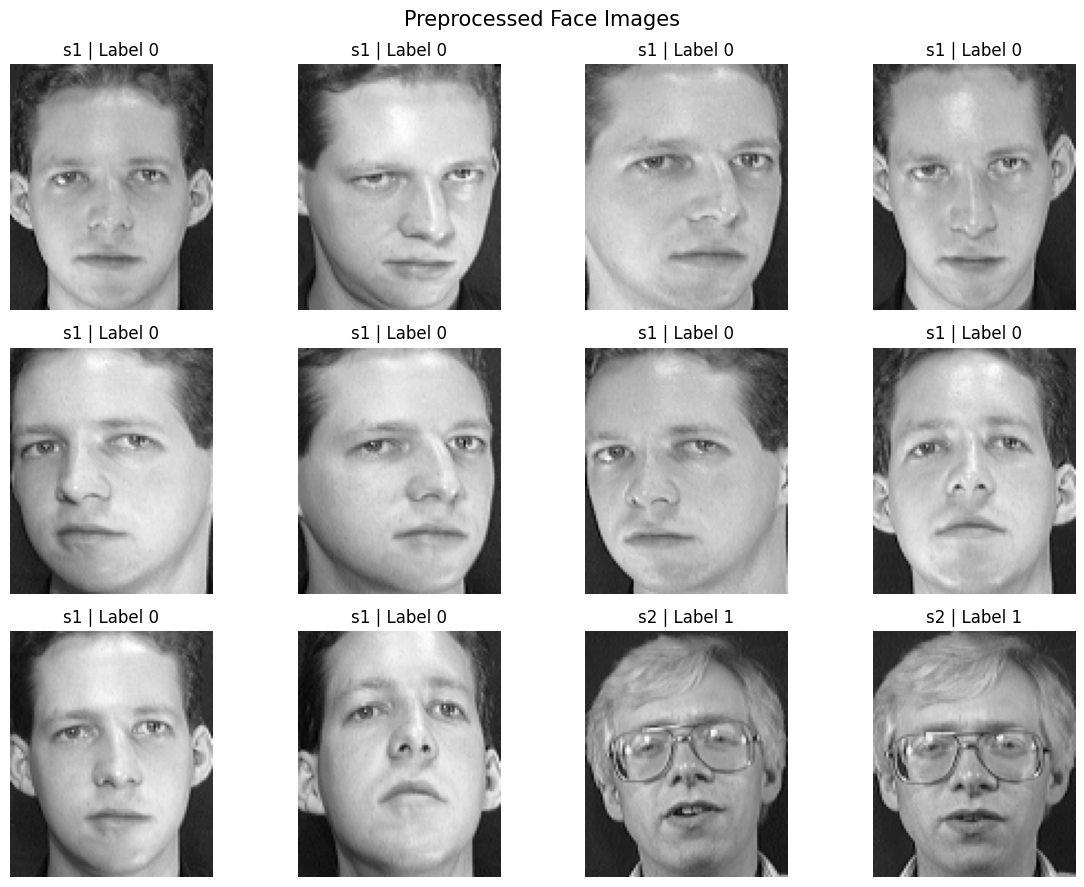

In [ ]:
# ============================================================
# CELL 14 — VISUALIZE PREPROCESSED DATASET
# ============================================================
plt.figure(figsize=(12, 9))
for i in range(12):
    plt.subplot(3, 4, i + 1)
    plt.imshow(
        X[i].squeeze(),
        cmap="gray"
    )
    plt.title(
        f"{persons[y[i]]} | Label {y[i]}"
    )
    plt.axis("off")
plt.suptitle(
    "Preprocessed Face Images",
    fontsize=15
)
plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# CELL 15 — IDENTITY-BASED TRAIN/TEST SPLIT
# ============================================================
# Split identities, not individual images
train_persons, test_persons = train_test_split(
    persons,
    test_size=0.20,
    random_state=RANDOM_SEED
)
# Sort for clear presentation
train_persons = sorted(
    train_persons,
    key=lambda x: int(x[1:])
)
test_persons = sorted(
    test_persons,
    key=lambda x: int(x[1:])
)
# Create masks using identity names
train_indices = [
    i for i, person in enumerate(
        [persons[label] for label in y]
    )
    if person in train_persons
]
test_indices = [
    i for i, person in enumerate(
        [persons[label] for label in y]
    )
    if person in test_persons
]
X_train = X[train_indices]
y_train = y[train_indices]

X_test = X[test_indices]
y_test = y[test_indices]
print("=" * 60)
print("IDENTITY-BASED TRAIN/TEST SPLIT")
print("=" * 60)
print("Training identities :", len(train_persons))
print("Testing identities  :", len(test_persons))
print("\nTraining identities:")
print(train_persons)
print("\nTesting identities:")
print(test_persons)
print("\nTraining images:", X_train.shape)
print("Testing images :", X_test.shape)

IDENTITY-BASED TRAIN/TEST SPLIT
Training identities : 32
Testing identities  : 8

Training identities:
['s1', 's2', 's3', 's4', 's6', 's7', 's8', 's9', 's10', 's11', 's12', 's14', 's15', 's18', 's19', 's21', 's22', 's23', 's24', 's25', 's26', 's29', 's30', 's31', 's32', 's33', 's34', 's35', 's36', 's37', 's39', 's40']

Testing identities:
['s5', 's13', 's16', 's17', 's20', 's27', 's28', 's38']

Training images: (320, 112, 92, 1)
Testing images : (80, 112, 92, 1)


In [ ]:
# ============================================================
# CELL 16 — VERIFY TRAIN/TEST IDENTITY SEPARATION
# ============================================================

overlap = set(train_persons).intersection(
    set(test_persons)
)

print("=" * 60)
print("TRAIN/TEST IDENTITY VERIFICATION")
print("=" * 60)

print("Common identities:", overlap)

if len(overlap) == 0:
    print("✓ No identity overlap detected.")
else:
    print("✗ Identity overlap detected.")

TRAIN/TEST IDENTITY VERIFICATION
Common identities: set()
✓ No identity overlap detected.


In [ ]:
# ============================================================
# CELL 17 — POSITIVE AND NEGATIVE PAIR GENERATION FUNCTION
# ============================================================

def create_pairs(images, labels, pairs_per_class=10):

    pairs = []
    pair_labels = []

    unique_classes = np.unique(labels)

    class_indices = {
        label: np.where(labels == label)[0]
        for label in unique_classes
    }

    rng = np.random.default_rng(RANDOM_SEED)

    for label in unique_classes:

        indices = class_indices[label]

        if len(indices) < 2:
            continue

        # -----------------------------
        # Positive pairs
        # -----------------------------
        for _ in range(pairs_per_class):

            idx1, idx2 = rng.choice(
                indices,
                size=2,
                replace=False
            )

            pairs.append([
                images[idx1],
                images[idx2]
            ])

            pair_labels.append(1)

        # -----------------------------
        # Negative pairs
        # -----------------------------
        for _ in range(pairs_per_class):

            other_classes = unique_classes[
                unique_classes != label
            ]

            other_label = rng.choice(
                other_classes
            )

            idx1 = rng.choice(indices)
            idx2 = rng.choice(
                class_indices[other_label]
            )

            pairs.append([
                images[idx1],
                images[idx2]
            ])

            pair_labels.append(0)

    pairs = np.array(
        pairs,
        dtype=np.float32
    )

    pair_labels = np.array(
        pair_labels,
        dtype=np.float32
    )

    # Shuffle all pairs
    shuffle_indices = rng.permutation(
        len(pairs)
    )

    pairs = pairs[shuffle_indices]
    pair_labels = pair_labels[shuffle_indices]

    return pairs, pair_labels


print("Pair generation function created successfully.")

Pair generation function created successfully.


In [ ]:
# ============================================================
# CELL 18 — GENERATE TRAINING PAIRS
# ============================================================

train_pairs, train_pair_labels = create_pairs(
    X_train,
    y_train,
    pairs_per_class=10
)

print("=" * 60)
print("TRAINING PAIRS")
print("=" * 60)

print("Training pairs shape :", train_pairs.shape)
print("Training labels shape:", train_pair_labels.shape)

print(
    "Positive pairs:",
    np.sum(train_pair_labels == 1)
)

print(
    "Negative pairs:",
    np.sum(train_pair_labels == 0)
)

TRAINING PAIRS
Training pairs shape : (640, 2, 112, 92, 1)
Training labels shape: (640,)
Positive pairs: 320
Negative pairs: 320


In [ ]:
# ============================================================
# CELL 19 — GENERATE TESTING PAIRS
# ============================================================

test_pairs, test_pair_labels = create_pairs(
    X_test,
    y_test,
    pairs_per_class=10
)

print("=" * 60)
print("TESTING PAIRS")
print("=" * 60)

print("Testing pairs shape :", test_pairs.shape)
print("Testing labels shape:", test_pair_labels.shape)

print(
    "Positive pairs:",
    np.sum(test_pair_labels == 1)
)

print(
    "Negative pairs:",
    np.sum(test_pair_labels == 0)
)

TESTING PAIRS
Testing pairs shape : (160, 2, 112, 92, 1)
Testing labels shape: (160,)
Positive pairs: 80
Negative pairs: 80


In [ ]:
# ============================================================
# CELL 20 — VERIFY BALANCED POSITIVE/NEGATIVE PAIRS
# ============================================================

train_positive = np.sum(
    train_pair_labels == 1
)

train_negative = np.sum(
    train_pair_labels == 0
)

test_positive = np.sum(
    test_pair_labels == 1
)

test_negative = np.sum(
    test_pair_labels == 0
)

print("=" * 60)
print("PAIR BALANCE VERIFICATION")
print("=" * 60)

print("TRAINING")
print("Positive:", train_positive)
print("Negative:", train_negative)

print("\nTESTING")
print("Positive:", test_positive)
print("Negative:", test_negative)

if train_positive == train_negative:
    print("\n✓ Training pairs are balanced.")

if test_positive == test_negative:
    print("✓ Testing pairs are balanced.")

PAIR BALANCE VERIFICATION
TRAINING
Positive: 320
Negative: 320

TESTING
Positive: 80
Negative: 80

✓ Training pairs are balanced.
✓ Testing pairs are balanced.


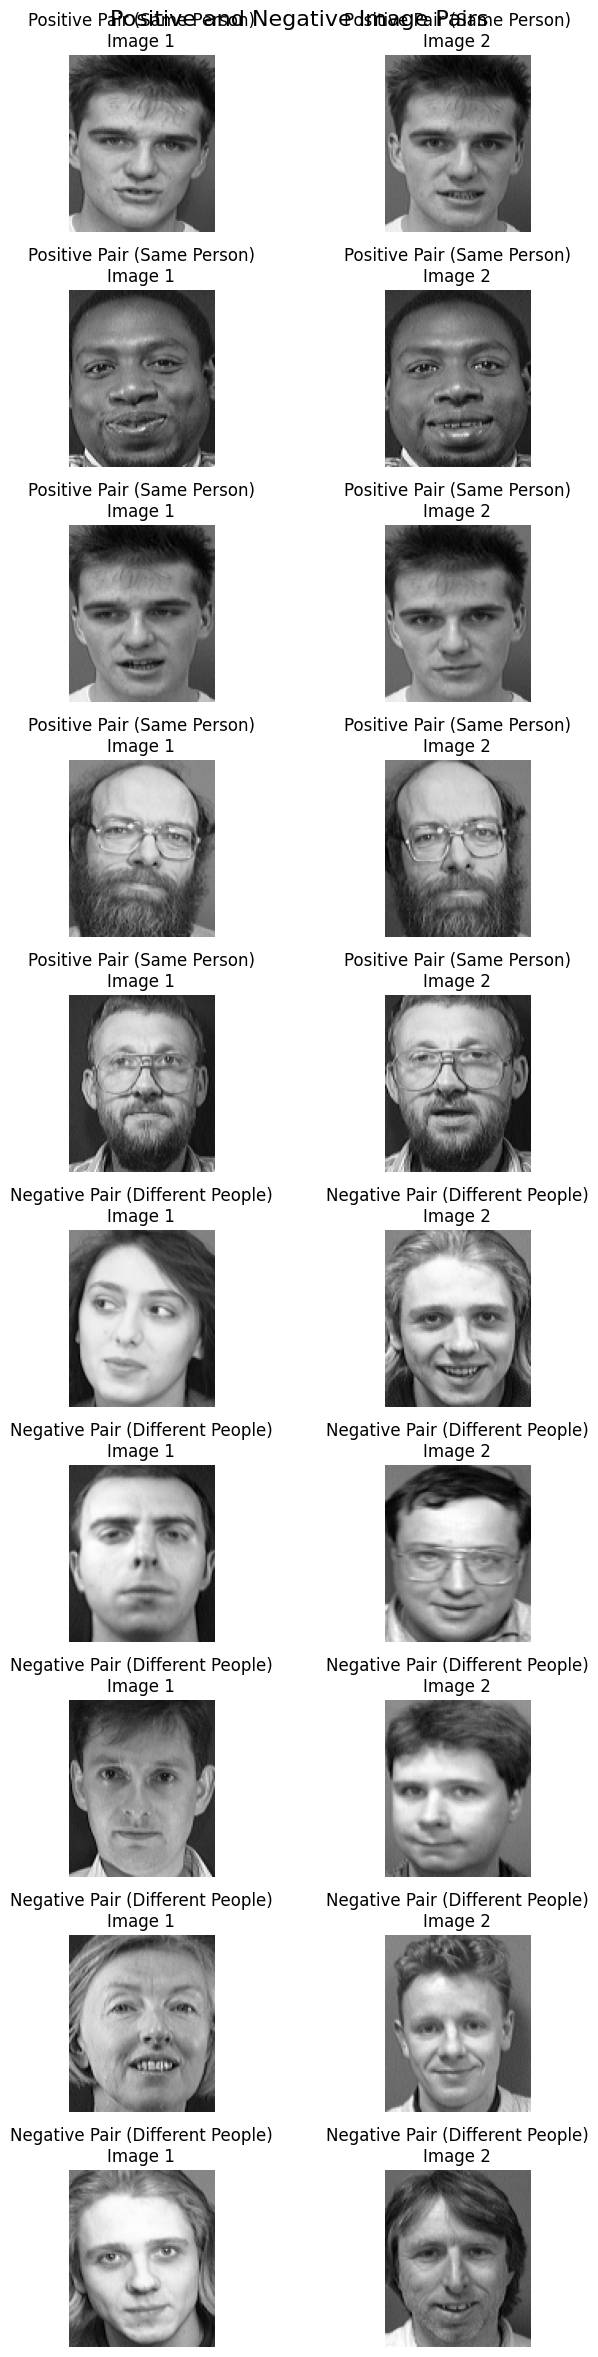

In [ ]:
# ============================================================
# CELL 21 — VISUALIZE POSITIVE AND NEGATIVE PAIRS
# ============================================================

def visualize_pairs(pairs, pair_labels, n=5):

    positive_indices = np.where(
        pair_labels == 1
    )[0][:n]

    negative_indices = np.where(
        pair_labels == 0
    )[0][:n]

    selected_indices = np.concatenate([
        positive_indices,
        negative_indices
    ])

    fig, axes = plt.subplots(
        10,
        2,
        figsize=(8, 24)
    )

    for row, pair_index in enumerate(
        selected_indices
    ):

        image1 = pairs[pair_index][0].squeeze()
        image2 = pairs[pair_index][1].squeeze()

        label = pair_labels[pair_index]

        pair_type = (
            "Positive Pair (Same Person)"
            if label == 1
            else
            "Negative Pair (Different People)"
        )

        axes[row, 0].imshow(
            image1,
            cmap="gray"
        )

        axes[row, 0].axis("off")

        axes[row, 0].set_title(
            f"{pair_type}\nImage 1"
        )

        axes[row, 1].imshow(
            image2,
            cmap="gray"
        )

        axes[row, 1].axis("off")

        axes[row, 1].set_title(
            f"{pair_type}\nImage 2"
        )

    plt.suptitle(
        "Positive and Negative Image Pairs",
        fontsize=16
    )

    plt.tight_layout()
    plt.show()


visualize_pairs(
    train_pairs,
    train_pair_labels,
    n=5
)

In [ ]:
# ============================================================
# CELL 22 — SHARED CNN FEATURE EXTRACTOR
# ============================================================

def create_shared_network():

    model = models.Sequential(
        name="Shared_CNN_Feature_Extractor"
    )

    model.add(
        layers.Input(
            shape=(IMG_HEIGHT, IMG_WIDTH, CHANNELS)
        )
    )

    model.add(
        layers.Conv2D(
            64,
            (3, 3),
            activation="relu"
        )
    )

    model.add(
        layers.MaxPooling2D()
    )

    model.add(
        layers.Conv2D(
            64,
            (3, 3),
            activation="relu"
        )
    )

    model.add(
        layers.Flatten()
    )

    model.add(
        layers.Dense(
            128,
            activation="sigmoid"
        )
    )

    return model


shared_cnn = create_shared_network()

print("Shared CNN created successfully.")

Shared CNN created successfully.


In [ ]:
# ============================================================
# CELL 23 — SHARED CNN MODEL SUMMARY
# ============================================================

print("=" * 60)
print("SHARED CNN FEATURE EXTRACTOR")
print("=" * 60)

shared_cnn.summary()

print(
    "\nTotal trainable parameters:",
    shared_cnn.count_params()
)

SHARED CNN FEATURE EXTRACTOR


Model: "Shared_CNN_Feature_Extractor"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 110, 90, 64)    │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 55, 45, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 53, 43, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 145856)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    18,669,696 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,707,264 (71.36 MB)

 Trainable params: 18,707,264 (71.36 MB)

 Non-trainable params: 0 (0.00 B)


Total trainable parameters: 18707264


In [ ]:
# ============================================================
# CELL 24 — TEST 128-DIMENSIONAL FEATURE EXTRACTION
# ============================================================

sample_batch = np.expand_dims(
    X[0],
    axis=0
)

feature_vector = shared_cnn.predict(
    sample_batch,
    verbose=0
)

print("=" * 60)
print("FEATURE VECTOR TEST")
print("=" * 60)

print("Input shape :", sample_batch.shape)
print("Output shape:", feature_vector.shape)

print("\nFeature vector:")
print(feature_vector[0])

print(
    "\nFeature vector dimensionality:",
    feature_vector.shape[1]
)

FEATURE VECTOR TEST
Input shape : (1, 112, 92, 1)
Output shape: (1, 128)

Feature vector:
[0.5480694  0.53025293 0.48803535 0.47775105 0.49473625 0.53007
 0.46549782 0.5282845  0.49549282 0.5240209  0.5190749  0.5068389
 0.46521235 0.4989326  0.52223366 0.54770195 0.4823756  0.4692821
 0.48696113 0.52423096 0.48780537 0.5073575  0.49402508 0.4703465
 0.4802695  0.4810296  0.49903753 0.49079785 0.51286215 0.5091926
 0.50037324 0.47046    0.51320374 0.49957523 0.47136322 0.52065593
 0.49811274 0.4830054  0.5208741  0.5379234  0.50230074 0.53018034
 0.48846394 0.5067385  0.4993754  0.50741726 0.47907066 0.46711785
 0.48632872 0.5159298  0.49042085 0.5252829  0.52971804 0.4858206
 0.48786688 0.49267995 0.5082234  0.5024296  0.52072847 0.48782203
 0.49967438 0.50450903 0.48382267 0.5028982  0.53847903 0.54153574
 0.49164164 0.49756643 0.5017032  0.48667988 0.50751823 0.50465494
 0.4971537  0.47757512 0.51258546 0.5403207  0.53529626 0.48326972
 0.49812704 0.4985062  0.5156535  0.49003085 0.

In [ ]:
# ============================================================
# CELL 25 — EUCLIDEAN DISTANCE FUNCTION
# ============================================================

def euclidean_distance(vectors):

    vector1, vector2 = vectors

    squared_difference = tf.square(
        vector1 - vector2
    )

    summed_difference = tf.reduce_sum(
        squared_difference,
        axis=1,
        keepdims=True
    )

    distance = tf.sqrt(
        tf.maximum(
            summed_difference,
            tf.keras.backend.epsilon()
        )
    )

    return distance


print("Euclidean distance function created.")

Euclidean distance function created.


In [ ]:
# ============================================================
# CELL 26 — SIAMESE NEURAL NETWORK
# ============================================================

input_a = layers.Input(
    shape=(IMG_HEIGHT, IMG_WIDTH, CHANNELS),
    name="Input_A"
)

input_b = layers.Input(
    shape=(IMG_HEIGHT, IMG_WIDTH, CHANNELS),
    name="Input_B"
)

# IMPORTANT:
# The same shared_cnn object is used for both inputs.
# Therefore both branches share exactly the same weights.

embedding_a = shared_cnn(input_a)
embedding_b = shared_cnn(input_b)

distance = layers.Lambda(
    euclidean_distance,
    name="Euclidean_Distance"
)([
    embedding_a,
    embedding_b
])

siamese_model = models.Model(
    inputs=[input_a, input_b],
    outputs=distance,
    name="Siamese_Face_Recognition_Network"
)

print("Siamese network created successfully.")

Siamese network created successfully.


In [ ]:
# ============================================================
# CELL 27 — SIAMESE MODEL SUMMARY
# ============================================================

print("=" * 60)
print("SIAMESE NEURAL NETWORK")
print("=" * 60)

siamese_model.summary()

SIAMESE NEURAL NETWORK


Model: "Siamese_Face_Recognition_Network"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ Input_A             │ (None, 112, 92,   │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Input_B             │ (None, 112, 92,   │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Shared_CNN_Feature… │ (None, 128)       │ 18,707,264 │ Input_A[0][0],    │
│ (Sequential)        │                   │            │ Input_B[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Euclidean_Distance  │ (None, 1)         │          0 │ Shared_CNN_Featu… │
│ (Lambda)            │                   │            │ Shared_CNN_Featu… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 18,707,264 (71.36 MB)

 Trainable params: 18,707,264 (71.36 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# ============================================================
# CELL 28 — TEST EUCLIDEAN DISTANCE
# ============================================================

test_image_1 = np.expand_dims(
    X[0],
    axis=0
)

test_image_2 = np.expand_dims(
    X[1],
    axis=0
)

distance_value = siamese_model.predict(
    [
        test_image_1,
        test_image_2
    ],
    verbose=0
)

print("=" * 60)
print("EUCLIDEAN DISTANCE TEST")
print("=" * 60)

print("Image 1 shape:", test_image_1.shape)
print("Image 2 shape:", test_image_2.shape)

print(
    "\nEuclidean distance:",
    float(distance_value[0][0])
)

EUCLIDEAN DISTANCE TEST
Image 1 shape: (1, 112, 92, 1)
Image 2 shape: (1, 112, 92, 1)

Euclidean distance: 0.05782049894332886


In [ ]:
# =========================
# CELL 29 — CONTRASTIVE LOSS + CUSTOM ACCURACY
# =========================

MARGIN = 1.0

def contrastive_loss(y_true, y_pred):
    """
    Contrastive loss:
    y = 1 -> same person
    y = 0 -> different persons
    """
    y_true = tf.cast(y_true, tf.float32)

    positive_loss = y_true * tf.square(y_pred)

    negative_loss = (
        (1 - y_true) *
        tf.square(tf.maximum(MARGIN - y_pred, 0))
    )

    return tf.reduce_mean(positive_loss + negative_loss)


def contrastive_accuracy(y_true, y_pred):
    """
    Distance < 0.5 -> same person (1)
    Distance >= 0.5 -> different person (0)
    """
    y_true = tf.cast(y_true, tf.float32)
    predictions = tf.cast(y_pred < 0.5, tf.float32)

    return tf.reduce_mean(
        tf.cast(tf.equal(y_true, predictions), tf.float32)
    )


print("Contrastive loss and custom accuracy defined.")
print("Margin:", MARGIN)

Contrastive loss and custom accuracy defined.
Margin: 1.0


In [ ]:
# =========================
# CELL 30 — TRAIN / VALIDATION PAIR SPLIT
# =========================

pair_indices = np.arange(len(train_pairs))

train_pair_idx, val_pair_idx = train_test_split(
    pair_indices,
    test_size=0.20,
    random_state=42,
    stratify=train_pair_labels
)

X_pair_train = [
    train_pairs[train_pair_idx, 0],
    train_pairs[train_pair_idx, 1]
]

y_pair_train = train_pair_labels[train_pair_idx].reshape(-1, 1)

X_pair_val = [
    train_pairs[val_pair_idx, 0],
    train_pairs[val_pair_idx, 1]
]

y_pair_val = train_pair_labels[val_pair_idx].reshape(-1, 1)

print("Training pairs:", len(y_pair_train))
print("Validation pairs:", len(y_pair_val))
print("Training label shape:", y_pair_train.shape)
print("Validation label shape:", y_pair_val.shape)

Training pairs: 512
Validation pairs: 128
Training label shape: (512, 1)
Validation label shape: (128, 1)


In [ ]:
# =========================
# CELL 31 — COMPILE SIAMESE NETWORK
# =========================

siamese_model.compile(
    optimizer=tf.keras.optimizers.Adam(),
    loss=contrastive_loss,
    metrics=[contrastive_accuracy]
)

print("Siamese network compiled successfully.")
siamese_model.summary()

Siamese network compiled successfully.


Model: "Siamese_Face_Recognition_Network"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ Input_A             │ (None, 112, 92,   │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Input_B             │ (None, 112, 92,   │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Shared_CNN_Feature… │ (None, 128)       │ 18,707,264 │ Input_A[0][0],    │
│ (Sequential)        │                   │            │ Input_B[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Euclidean_Distance  │ (None, 1)         │          0 │ Shared_CNN_Featu… │
│ (Lambda)            │                   │            │ Shared_CNN_Featu… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 18,707,264 (71.36 MB)

 Trainable params: 18,707,264 (71.36 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# =========================
# CELL 32 — TRAIN SIAMESE NETWORK
# =========================

history = siamese_model.fit(
    X_pair_train,
    y_pair_train,
    validation_data=(X_pair_val, y_pair_val),
    epochs=10,
    batch_size=128,
    verbose=1
)

Epoch 1/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 47s 12s/step - contrastive_accuracy: 0.7773 - loss: 0.1862 - val_contrastive_accuracy: 0.8672 - val_loss: 0.1118
Epoch 2/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 34s 8s/step - contrastive_accuracy: 0.9512 - loss: 0.0639 - val_contrastive_accuracy: 0.8828 - val_loss: 0.0849
Epoch 3/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 33s 9s/step - contrastive_accuracy: 0.9844 - loss: 0.0421 - val_contrastive_accuracy: 0.9453 - val_loss: 0.0729
Epoch 4/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 40s 8s/step - contrastive_accuracy: 0.9961 - loss: 0.0275 - val_contrastive_accuracy: 0.9375 - val_loss: 0.0650
Epoch 5/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 32s 9s/step - contrastive_accuracy: 1.0000 - loss: 0.0192 - val_contrastive_accuracy: 0.9297 - val_loss: 0.0624
Epoch 6/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 40s 8s/step - contrastive_accuracy: 1.0000 - loss: 0.0140 - val_contrastive_accuracy: 0.9688 - val_loss: 0.0496
Epoch 7/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 41s 8s/step - contrastive_accuracy: 1.0000 - loss: 0.0098 - val_contrastive

In [ ]:
# =========================
# CELL 33 — FINAL TRAINING RESULTS
# =========================

final_train_loss = history.history["loss"][-1]
final_train_accuracy = history.history["contrastive_accuracy"][-1]

final_val_loss = history.history["val_loss"][-1]
final_val_accuracy = history.history["val_contrastive_accuracy"][-1]

print("Final Training Loss     :", round(final_train_loss, 4))
print("Final Training Accuracy :", round(final_train_accuracy, 4))
print("Final Validation Loss   :", round(final_val_loss, 4))
print("Final Validation Accuracy:", round(final_val_accuracy, 4))

Final Training Loss     : 0.0042
Final Training Accuracy : 1.0
Final Validation Loss   : 0.0433
Final Validation Accuracy: 0.9844


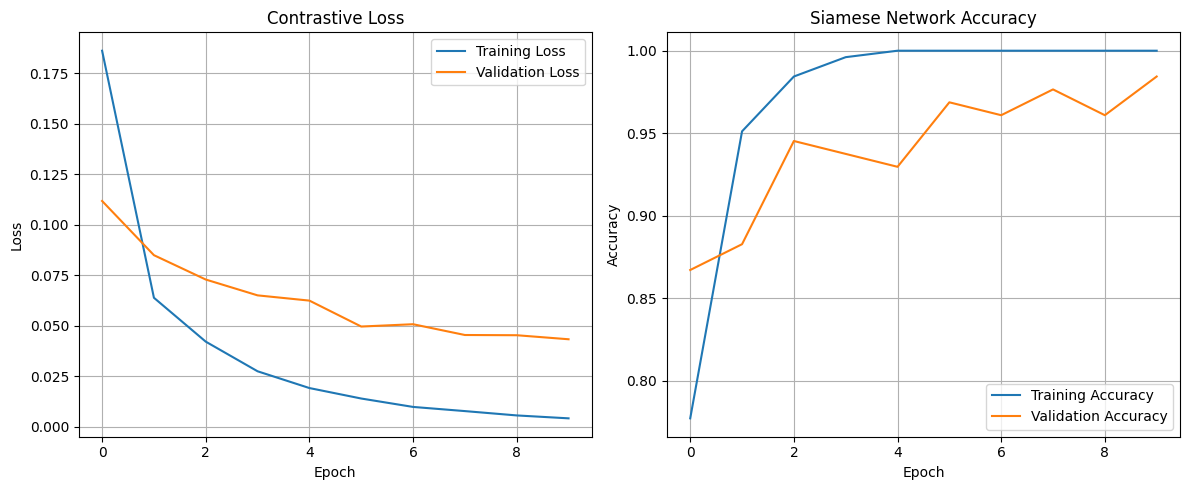

In [ ]:
# =========================
# CELL 34 — TRAINING HISTORY PLOTS
# =========================

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Contrastive Loss")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history.history["contrastive_accuracy"], label="Training Accuracy")
plt.plot(history.history["val_contrastive_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Siamese Network Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
# =========================
# CELL 35 — TEST SET EVALUATION
# =========================

X_pair_test = [
    test_pairs[:, 0],
    test_pairs[:, 1]
]

y_pair_test = test_pair_labels.reshape(-1, 1)

test_loss, test_accuracy = siamese_model.evaluate(
    X_pair_test,
    y_pair_test,
    batch_size=128,
    verbose=1
)

print("\nTest Loss     :", round(test_loss, 4))
print("Test Accuracy :", round(test_accuracy, 4))

2/2 ━━━━━━━━━━━━━━━━━━━━ 2s 421ms/step - contrastive_accuracy: 0.8242 - loss: 0.1272

Test Loss     : 0.1272
Test Accuracy : 0.8242


In [ ]:
# =========================
# CELL 36 — SAVE SIAMESE MODEL
# =========================

MODEL_PATH = "/content/models/siamese_nn.h5"

siamese_model.save(MODEL_PATH)

print("Siamese model saved successfully!")
print("Model path:", MODEL_PATH)
print("File exists:", os.path.exists(MODEL_PATH))

Siamese model saved successfully!
Model path: /content/models/siamese_nn.h5
File exists: True


In [ ]:
# =========================
# CELL 37 — SAVE SHARED CNN
# =========================

SHARED_CNN_PATH = "/content/models/shared_cnn.h5"

shared_cnn.save(SHARED_CNN_PATH)

print("Shared CNN saved successfully!")
print("Path:", SHARED_CNN_PATH)
print("File exists:", os.path.exists(SHARED_CNN_PATH))

Shared CNN saved successfully!
Path: /content/models/shared_cnn.h5
File exists: True


In [ ]:
# =========================
# CELL 38 — VERIFY SAVED MODELS
# =========================

print("Saved model files:")

for file in os.listdir("/content/models"):
    print(" -", file)

Saved model files:
 - shared_cnn.h5
 - siamese_nn.h5


In [ ]:
# =========================
# CELL 39 — VIOLA-JONES FACE DETECTOR
# =========================

import cv2

CASCADE_PATH = cv2.data.haarcascades + "haarcascade_frontalface_default.xml"

face_cascade = cv2.CascadeClassifier(CASCADE_PATH)

print("Haar Cascade loaded successfully!")
print("Cascade path:", CASCADE_PATH)

Haar Cascade loaded successfully!
Cascade path: /usr/local/lib/python3.13/dist-packages/cv2/data/haarcascade_frontalface_default.xml


In [ ]:
# =========================
# CELL 40 — FACE DETECTION FUNCTION
# =========================

def detect_face(image):
    """
    Detect the largest frontal face using Viola-Jones Haar Cascade.

    Returns:
        face_crop: cropped grayscale face
        bbox: (x, y, w, h)
    """

    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    faces = face_cascade.detectMultiScale(
        gray,
        scaleFactor=1.1,
        minNeighbors=5,
        minSize=(30, 30)
    )

    if len(faces) == 0:
        return None, None

    # Select largest detected face
    x, y, w, h = max(
        faces,
        key=lambda box: box[2] * box[3]
    )

    face_crop = gray[y:y+h, x:x+w]

    return face_crop, (x, y, w, h)


print("Face detection function created.")

Face detection function created.


In [ ]:
# =========================
# CELL 41 — TEST FACE DETECTION
# =========================

image_path = os.path.join(DATASET_PATH, "s1", "1.pgm")

image = cv2.imread(image_path)

face_crop, bbox = detect_face(image)

print("Image path:", image_path)
print("Detected bounding box:", bbox)

if face_crop is not None:
    print("Detected face shape:", face_crop.shape)
else:
    print("No face detected.")

Image path: /content/s1/1.pgm
Detected bounding box: (np.int32(5), np.int32(23), np.int32(81), np.int32(81))
Detected face shape: (81, 81)


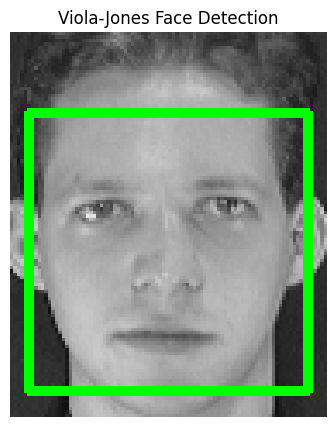

In [ ]:
# =========================
# CELL 42 — VISUALIZE FACE DETECTION
# =========================

display_image = image.copy()

if bbox is not None:
    x, y, w, h = bbox

    cv2.rectangle(
        display_image,
        (x, y),
        (x + w, y + h),
        (0, 255, 0),
        2
    )

plt.figure(figsize=(6, 5))
plt.imshow(cv2.cvtColor(display_image, cv2.COLOR_BGR2RGB))
plt.title("Viola-Jones Face Detection")
plt.axis("off")
plt.show()

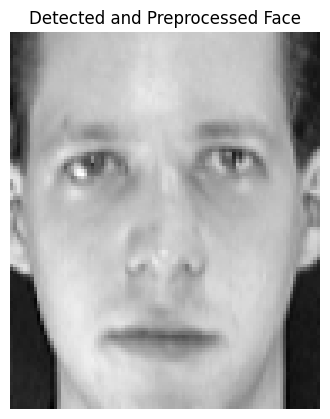

Resized face shape: (112, 92)
Normalized range: 0.08235294 to 0.8392157


In [ ]:
# =========================
# CELL 43 — CROP + RESIZE DETECTED FACE
# =========================

if face_crop is not None:

    resized_face = cv2.resize(
        face_crop,
        (IMG_WIDTH, IMG_HEIGHT)
    )

    normalized_face = resized_face.astype("float32") / 255.0

    plt.figure(figsize=(4, 5))
    plt.imshow(normalized_face, cmap="gray")
    plt.title("Detected and Preprocessed Face")
    plt.axis("off")
    plt.show()

    print("Resized face shape:", resized_face.shape)
    print("Normalized range:",
          normalized_face.min(),
          "to",
          normalized_face.max())

else:
    print("No face available for preprocessing.")

In [ ]:
# =========================
# CELL 44 — FACE EMBEDDING FUNCTION
# =========================

def preprocess_detected_face(face):
    """
    Preprocess a detected grayscale face
    for the Siamese shared CNN.
    """

    face = cv2.resize(
        face,
        (IMG_WIDTH, IMG_HEIGHT)
    )

    face = face.astype("float32") / 255.0

    face = np.expand_dims(face, axis=-1)
    face = np.expand_dims(face, axis=0)

    return face


def generate_embedding(face):
    """
    Generate a 128-dimensional face embedding.
    """

    processed_face = preprocess_detected_face(face)

    embedding = shared_cnn.predict(
        processed_face,
        verbose=0
    )

    return embedding[0]


print("Embedding functions created.")

Embedding functions created.


In [ ]:
# =========================
# CELL 45 — GENERATE 128-D FACE EMBEDDING
# =========================

if face_crop is not None:

    test_embedding = generate_embedding(face_crop)

    print("Embedding shape:", test_embedding.shape)
    print("Embedding dimension:", len(test_embedding))
    print("First 10 values:")
    print(test_embedding[:10])

else:
    print("No face detected.")

Embedding shape: (128,)
Embedding dimension: 128
First 10 values:
[1.0000000e+00 1.0000000e+00 1.6386279e-07 1.4210688e-06 8.3831370e-01
 1.0000000e+00 1.3880789e-08 9.9999934e-01 6.1313665e-01 1.0000000e+00]


In [ ]:
# =========================
# CELL 46 — REGISTERED USERS STORAGE
# =========================

REGISTERED_USERS_PATH = "/content/registered_users"

os.makedirs(REGISTERED_USERS_PATH, exist_ok=True)

print("Registered users directory:", REGISTERED_USERS_PATH)

Registered users directory: /content/registered_users


In [ ]:
# =========================
# CELL 47 — USER REGISTRATION FUNCTION
# =========================

def register_user(user_id, user_name, face_images):
    """
    Register a user using multiple face images.

    Parameters:
        user_id   : unique user ID
        user_name : user's name
        face_images: list of detected grayscale face images

    Returns:
        user_data containing user information and averaged embedding
    """

    embeddings = []

    for face in face_images:

        embedding = generate_embedding(face)
        embeddings.append(embedding)

    if len(embeddings) == 0:
        return None

    # Average multiple embeddings for a stable representation
    final_embedding = np.mean(
        np.array(embeddings),
        axis=0
    )

    user_data = {
        "user_id": str(user_id),
        "name": str(user_name),
        "embedding": final_embedding.tolist()
    }

    user_file = os.path.join(
        REGISTERED_USERS_PATH,
        f"{user_id}.json"
    )

    with open(user_file, "w") as f:
        json.dump(user_data, f, indent=4)

    return user_data


print("User registration function created.")

User registration function created.


In [ ]:
# =========================
# CELL 48A — IMPORT JSON
# =========================

import json

print("JSON module imported successfully.")

JSON module imported successfully.


In [ ]:
# =========================
# CELL 48 — TEST USER REGISTRATION
# =========================

sample_faces = []

for i in range(1, 6):

    path = os.path.join(
        DATASET_PATH,
        "s1",
        f"{i}.pgm"
    )

    img = cv2.imread(
        path,
        cv2.IMREAD_GRAYSCALE
    )

    if img is not None:
        sample_faces.append(img)

print("Number of sample faces:", len(sample_faces))

registered_user = register_user(
    user_id="TEST001",
    user_name="Test User",
    face_images=sample_faces
)

if registered_user is not None:
    print("User registered successfully!")
    print("User ID:", registered_user["user_id"])
    print("Name:", registered_user["name"])
    print("Embedding dimension:", len(registered_user["embedding"]))
else:
    print("Registration failed.")

Number of sample faces: 5
User registered successfully!
User ID: TEST001
Name: Test User
Embedding dimension: 128


In [ ]:
# =========================
# CELL 49 — VERIFY REGISTERED USER
# =========================

user_file = os.path.join(
    REGISTERED_USERS_PATH,
    "TEST001.json"
)

print("Registered user file:", user_file)
print("File exists:", os.path.exists(user_file))

if os.path.exists(user_file):

    with open(user_file, "r") as f:
        saved_user = json.load(f)

    print("\nRegistered User Information")
    print("--------------------------")
    print("User ID:", saved_user["user_id"])
    print("Name:", saved_user["name"])
    print("Embedding dimension:", len(saved_user["embedding"]))

Registered user file: /content/registered_users/TEST001.json
File exists: True

Registered User Information
--------------------------
User ID: TEST001
Name: Test User
Embedding dimension: 128


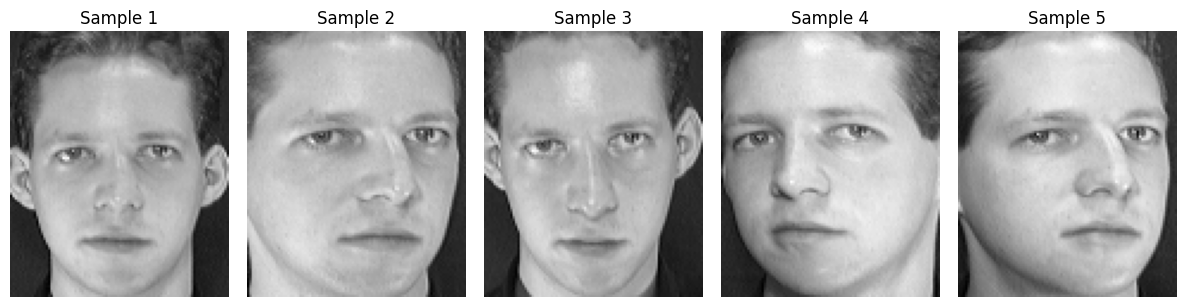

In [ ]:
# =========================
# CELL 50 — DISPLAY REGISTERED FACE SAMPLES
# =========================

plt.figure(figsize=(12, 3))

for i, face in enumerate(sample_faces):

    plt.subplot(1, len(sample_faces), i + 1)
    plt.imshow(face, cmap="gray")
    plt.title(f"Sample {i+1}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# =========================
# CELL 51 — LOAD REGISTERED USERS
# =========================

def load_registered_users():
    """
    Load all registered users and their embeddings.
    """

    users = {}

    for filename in os.listdir(REGISTERED_USERS_PATH):

        if filename.endswith(".json"):

            filepath = os.path.join(
                REGISTERED_USERS_PATH,
                filename
            )

            with open(filepath, "r") as f:
                user_data = json.load(f)

            users[user_data["user_id"]] = user_data

    return users


registered_users = load_registered_users()

print("Number of registered users:", len(registered_users))

for user_id, user in registered_users.items():
    print(
        user_id,
        "->",
        user["name"],
        "| Embedding:",
        len(user["embedding"])
    )

Number of registered users: 1
TEST001 -> Test User | Embedding: 128


In [ ]:
# =========================
# CELL 52 — EUCLIDEAN DISTANCE
# =========================

def calculate_distance(embedding1, embedding2):
    """
    Calculate Euclidean distance between two face embeddings.
    """

    embedding1 = np.asarray(
        embedding1,
        dtype=np.float32
    )

    embedding2 = np.asarray(
        embedding2,
        dtype=np.float32
    )

    return float(
        np.linalg.norm(embedding1 - embedding2)
    )


print("Euclidean distance function ready.")

Euclidean distance function ready.


In [ ]:
# =========================
# CELL 53 — VALIDATION THRESHOLD SELECTION
# =========================

val_distances = siamese_model.predict(
    X_pair_val,
    verbose=0
).flatten()

val_labels = y_pair_val.flatten()

thresholds = np.linspace(
    val_distances.min(),
    val_distances.max(),
    200
)

best_threshold = 0.0
best_accuracy = 0.0

for threshold in thresholds:

    predictions = (
        val_distances < threshold
    ).astype(int)

    accuracy = np.mean(
        predictions == val_labels
    )

    if accuracy > best_accuracy:
        best_accuracy = accuracy
        best_threshold = threshold

print("Best validation threshold:", round(best_threshold, 4))
print("Validation accuracy at threshold:",
      round(best_accuracy, 4))

Best validation threshold: 0.5319
Validation accuracy at threshold: 0.9922


In [ ]:
# =========================
# CELL 54 — FACE RECOGNITION FUNCTION
# =========================

def recognize_face(face, registered_users, threshold):
    """
    Compare a detected face against all registered users.

    Returns:
        recognized user information,
        minimum distance,
        or Unknown.
    """

    query_embedding = generate_embedding(face)

    best_user = None
    best_distance = float("inf")

    for user_id, user_data in registered_users.items():

        stored_embedding = np.array(
            user_data["embedding"],
            dtype=np.float32
        )

        distance = calculate_distance(
            query_embedding,
            stored_embedding
        )

        if distance < best_distance:
            best_distance = distance
            best_user = user_data

    if best_distance < threshold:
        return best_user, best_distance

    return None, best_distance


print("Face recognition function created.")

Face recognition function created.


In [ ]:
# =========================
# CELL 55 — REGISTERED USER RECOGNITION
# SCREENSHOT: 16_registered_recognition.png
# =========================

test_path = os.path.join(
    DATASET_PATH,
    "s1",
    "6.pgm"
)

test_image = cv2.imread(
    test_path,
    cv2.IMREAD_GRAYSCALE
)

recognized_user, distance = recognize_face(
    test_image,
    registered_users,
    best_threshold
)

print("Test image:", test_path)
print("Distance:", round(distance, 4))

if recognized_user is not None:
    print("RESULT: RECOGNIZED")
    print("User ID:", recognized_user["user_id"])
    print("Name:", recognized_user["name"])
else:
    print("RESULT: UNKNOWN")

Test image: /content/s1/6.pgm
Distance: 0.1289
RESULT: RECOGNIZED
User ID: TEST001
Name: Test User


In [ ]:
# =========================
# CELL 56 — UNKNOWN USER RECOGNITION
# =========================

unknown_path = os.path.join(
    DATASET_PATH,
    "s2",
    "1.pgm"
)

unknown_image = cv2.imread(
    unknown_path,
    cv2.IMREAD_GRAYSCALE
)

recognized_user, distance = recognize_face(
    unknown_image,
    registered_users,
    best_threshold
)

print("Test image:", unknown_path)
print("Distance:", round(distance, 4))

if recognized_user is not None:
    print("RESULT: RECOGNIZED")
    print("User ID:", recognized_user["user_id"])
    print("Name:", recognized_user["name"])
else:
    print("RESULT: UNKNOWN")

Test image: /content/s2/1.pgm
Distance: 0.7156
RESULT: UNKNOWN


In [ ]:
# =========================
# CELL 57 — NO-FACE TEST
# =========================

blank_image = np.zeros(
    (300, 300, 3),
    dtype=np.uint8
)

face_crop, bbox = detect_face(blank_image)

if face_crop is None:
    print("RESULT: NO FACE DETECTED")
else:
    print("Face detected unexpectedly.")

RESULT: NO FACE DETECTED


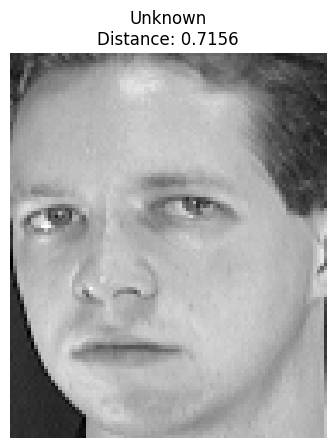

In [ ]:
# =========================
# CELL 58 — DISPLAY RECOGNITION RESULT
# =========================

plt.figure(figsize=(5, 5))

plt.imshow(test_image, cmap="gray")

if recognized_user is not None:
    title = (
        f"Recognized: {recognized_user['name']}\n"
        f"Distance: {distance:.4f}"
    )
else:
    title = (
        f"Unknown\n"
        f"Distance: {distance:.4f}"
    )

plt.title(title)
plt.axis("off")
plt.show()

In [ ]:
# =========================
# CELL 59 — SAVE RECOGNITION THRESHOLD
# =========================

threshold_data = {
    "threshold": float(best_threshold),
    "validation_accuracy": float(best_accuracy)
}

THRESHOLD_PATH = "/content/models/threshold.json"

with open(THRESHOLD_PATH, "w") as f:
    json.dump(threshold_data, f, indent=4)

print("Threshold saved successfully!")
print("Threshold:", best_threshold)
print("Validation accuracy:", best_accuracy)
print("Path:", THRESHOLD_PATH)

Threshold saved successfully!
Threshold: 0.5318608
Validation accuracy: 0.9921875
Path: /content/models/threshold.json


In [ ]:
# =========================
# CELL 60 — CREATE MODEL PACKAGE
# =========================

import shutil

MODEL_PACKAGE = "/content/Siamese_Face_Recognition_Models.zip"

with zipfile.ZipFile(MODEL_PACKAGE, "w") as zipf:

    zipf.write(
        "/content/models/siamese_nn.h5",
        arcname="siamese_nn.h5"
    )

    zipf.write(
        "/content/models/shared_cnn.h5",
        arcname="shared_cnn.h5"
    )

    zipf.write(
        "/content/models/threshold.json",
        arcname="threshold.json"
    )

print("Model package created:")
print(MODEL_PACKAGE)

Model package created:
/content/Siamese_Face_Recognition_Models.zip


In [ ]:
# =========================
# CELL 61 — DOWNLOAD MODEL PACKAGE
# =========================

from google.colab import files

files.download(
    "/content/Siamese_Face_Recognition_Models.zip"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>